# Reproducible readiness audit when data are absent

**Level 3 — Research critique**  
**Prerequisites:** Levels 1–2 and inverse-problem fundamentals; 35 min.

## Objectives

Trace the evidence from source contract to result. State units and assumptions, reproduce the calculation, and identify which inference the evidence cannot support.

## Setup

Uses repository modules and committed records through a discovered root; it downloads and mutates nothing. Install exact pins: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Data

Provider-linked Slagdump source is documented, but no raw ERT file is present; upstream counts are metadata only.

## Method

A defensible ERT interpretation requires licensed source bytes, geometry and array type, QC/reciprocity, topographic mesh, data-error model, inverse settings, residuals, withheld observations and sensitivity analysis. A smooth section alone does not establish data support. This notebook audits four gates—source documented, bytes present, processing contract available, result reproducible—and verifies local absence rather than silently replacing the survey with an upstream example. The figure contrasts the documented default/alternate cell-size controls in metres; mesh topology and cell count still depend on missing survey geometry. Conclusion: the product pipeline exists, but this field result cannot be reproduced from this checkout. A subsequent run must start from the acquired, rights-cleared bytes and preserve their hash.

The geometric factor converts resistance under a half-space assumption; it is not true resistivity at a depth. Many cells affect each datum, creating broad sensitivity and depth-dependent resolution. Log parameterization protects positivity but changes smoothness meaning. Mesh refinement must be judged by stable predictions under comparable data fit, not cell size alone.

## State of the art

The research context is not a leaderboard: separate published formulation from the product implementation and its committed evidence. A claim of advance would require independent held-out domains, calibrated uncertainty and replication.

## Results

Read the physical axes and units; distinguish data fit, error against synthetic truth and agreement with analyst labels. Recomputed values must agree with the serialized receipt. A plotted model alone does not establish uniqueness, field transfer or resolution.

### Diagnostic 1

Inspect the committed case record and provenance.

In [1]:
from pathlib import Path
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'matplotlib']})
import numpy as np
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
# Verify source ledger and local presence of raw ERT inputs.
import json
from pathlib import Path
ledger=json.loads((root/"data/source-ledger.json").read_text(encoding="utf-8")); print("ledger mentions Slagdump:","slagdump" in json.dumps(ledger).lower()); raw=list((root/"data").rglob("*.ohm")); print("local .ohm files:",raw,"; inversion from field arrays possible:",bool(raw))

Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
ledger mentions Slagdump: True
local .ohm files: [] ; inversion from field arrays possible: False


### Diagnostic 2

Compute the declared comparison and plot it with physical units.

paraDX [0.3, 0.45] dimensionless; maximum cell size [10.0, 15.0] m; alternate/default ratios 1.5 1.5


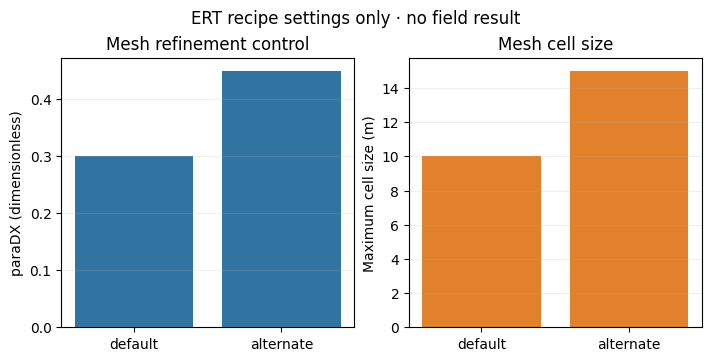

In [2]:
# Read default and alternate mesh parameters from the source AST; no mesh or field model is generated.
import ast
import numpy as np
import matplotlib.pyplot as plt
tree=ast.parse((root/"data-pipeline/ert.py").read_text(encoding="utf-8")); assigns={n.targets[0].id:n.value for n in tree.body if isinstance(n,ast.Assign) and isinstance(n.targets[0],ast.Name)}
default=ast.literal_eval(assigns["INVERSE_OPTIONS"]); alt_node=assigns["ALTERNATE_MESH_OPTIONS"]; overrides={k:ast.literal_eval(v) for k,v in zip([k.value for k in alt_node.keys if k is not None],[v for v in alt_node.values if not isinstance(v,ast.Name)])}; alternate={**default,**overrides}
labels=["default","alternate"]; dx=[default["paraDX"],alternate["paraDX"]]; cell=[default["paraMaxCellSize"],alternate["paraMaxCellSize"]]; print("paraDX",dx,"dimensionless; maximum cell size",cell,"m; alternate/default ratios",cell[1]/cell[0],dx[1]/dx[0])
fig,ax=plt.subplots(1,2,figsize=(7,3.5),constrained_layout=True); x=np.arange(2); ax[0].bar(x,dx,color="#3274a1"); ax[0].set(xticks=x,xticklabels=labels,ylabel="paraDX (dimensionless)",title="Mesh refinement control"); ax[1].bar(x,cell,color="#e1812c"); ax[1].set(xticks=x,xticklabels=labels,ylabel="Maximum cell size (m)",title="Mesh cell size"); [a.grid(axis="y",alpha=.2) for a in ax]; fig.suptitle("ERT recipe settings only · no field result"); plt.show()

### Experiment: a linearized sensitivity proxy and regularization trade-off

The real DC problem is `∇·(σ∇u)=-Iδ`; a defensible field inversion requires the numerical forward solver, surveyed electrodes/topography and error model. Raw source bytes are absent here. This experiment therefore uses an **explicit teaching proxy**, not the product PDE solver: rows of `G` are broad depth-decaying kernels for different electrode spacings. Inspect singular values and solve `min ||Gm-d||² + λ||m||²` for a synthetic log-resistivity perturbation, with alternating spacings held out. The sweep demonstrates how λ changes fit and model recovery under limited sensitivity. It cannot validate the field case, topographic correction or product solver.

Teaching proxy matrix (18, 30) rank 13 condition 2.72e+13
lambda=0.0001; train RMSE=0.004086; held-out RMSE=0.008446; relative model error=0.634
lambda=0.01; train RMSE=0.00848; held-out RMSE=0.02045; relative model error=0.724
lambda=1; train RMSE=0.08764; held-out RMSE=0.08576; relative model error=0.830


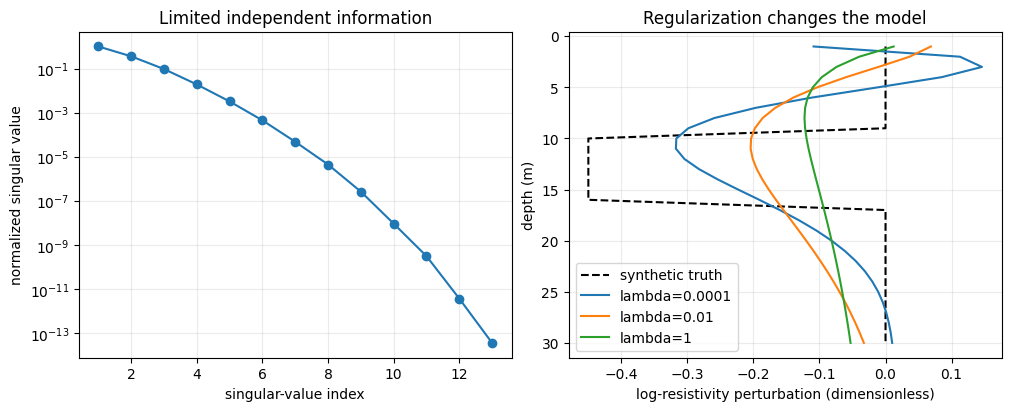

Linearized teaching proxy only; not a field result or product-solver receipt.


In [3]:
# Execute the documented experiment with the repository evidence.
import numpy as np, matplotlib.pyplot as plt
z=np.linspace(1,30,30); spacing=np.geomspace(2,40,18)
G=np.exp(-z[None,:]/spacing[:,None]); G/=np.linalg.norm(G,axis=1,keepdims=True)
m_true=np.zeros_like(z); m_true[(z>=10)&(z<=16)]=-.45
rng=np.random.default_rng(314159); d=G@m_true+rng.normal(0,.006,len(spacing))
train=np.arange(len(spacing))%4!=0; hold=~train; s=np.linalg.svd(G[train],compute_uv=False)
print("Teaching proxy matrix",G.shape,"rank",np.linalg.matrix_rank(G[train]),"condition",f"{s[0]/s[-1]:.2e}")
results=[]
for lam in (1e-4,1e-2,1.):
    m=np.linalg.solve(G[train].T@G[train]+lam*np.eye(len(z)),G[train].T@d[train])
    tr=np.sqrt(np.mean((G[train]@m-d[train])**2)); ho=np.sqrt(np.mean((G[hold]@m-d[hold])**2)); err=np.linalg.norm(m-m_true)/np.linalg.norm(m_true)
    results.append((lam,m)); print(f"lambda={lam:g}; train RMSE={tr:.4g}; held-out RMSE={ho:.4g}; relative model error={err:.3f}")
fig,ax=plt.subplots(1,2,figsize=(10,4),constrained_layout=True); ax[0].semilogy(np.arange(1,len(s)+1),s/s[0],"o-"); ax[0].set(xlabel="singular-value index",ylabel="normalized singular value",title="Limited independent information"); ax[0].grid(alpha=.25)
ax[1].plot(m_true,z,"k--",label="synthetic truth")
for lam,m in results: ax[1].plot(m,z,label=f"lambda={lam:g}")
ax[1].invert_yaxis(); ax[1].set(xlabel="log-resistivity perturbation (dimensionless)",ylabel="depth (m)",title="Regularization changes the model"); ax[1].legend(); ax[1].grid(alpha=.25); plt.show()
print("Linearized teaching proxy only; not a field result or product-solver receipt.")

## Summary

Conclusion is conditional on geometry, acquisition, noise model, split, parameterization and source rights. Preserve negative cases and name the next observation or control needed.

## References

- [https://www.pygimli.org/user-guide/inversion/](https://www.pygimli.org/user-guide/inversion/)
- [https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/](https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/)